# Clustering con Python

### Importar el dataset

In [1]:
import pandas as pd

In [4]:
df = pd.read_csv("../datasets/wine/winequality-red.csv", sep=";")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [5]:
df.shape

(1599, 12)

In [6]:
import matplotlib.pyplot as plt

(array([ 10.,   0.,  53.,   0., 681.,   0., 638.,   0., 199.,  18.]),
 array([3. , 3.5, 4. , 4.5, 5. , 5.5, 6. , 6.5, 7. , 7.5, 8. ]),
 <BarContainer object of 10 artists>)

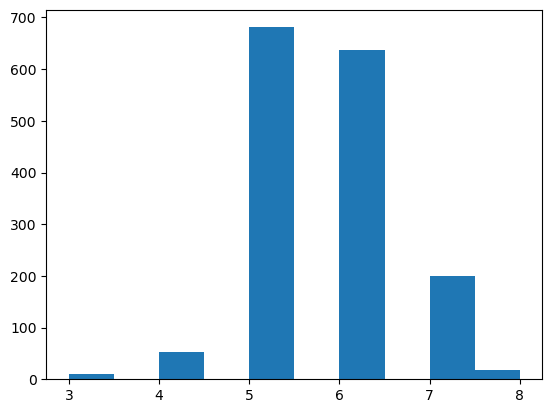

In [7]:
plt.hist(df["quality"])

In [8]:
df.groupby("quality").mean()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,8.360000,0.884500,0.171000,2.635000,0.122500,11.000000,24.900000,0.997464,3.398000,0.570000,9.955000
4,7.779245,0.693962,0.174151,2.694340,0.090679,12.264151,36.245283,0.996542,3.381509,0.596415,10.265094
5,8.167254,0.577041,0.243686,2.528855,0.092736,16.983847,56.513950,0.997104,3.304949,0.620969,9.899706
6,8.347179,0.497484,0.273824,2.477194,0.084956,15.711599,40.869906,0.996615,3.318072,0.675329,10.629519
7,8.872362,0.403920,0.375176,2.720603,0.076588,14.045226,35.020101,0.996104,3.290754,0.741256,11.465913
8,8.566667,0.423333,0.391111,2.577778,0.068444,13.277778,33.444444,0.995212,3.267222,0.767778,12.094444


### Normalizacion de los datos

In [9]:
df_norm = (df-df.min())/(df.max()-df.min())
df_norm.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846,0.4
1,0.283186,0.520548,0.00,0.116438,0.143573,0.338028,0.215548,0.494126,0.362205,0.209581,0.215385,0.4
2,0.283186,0.438356,0.04,0.095890,0.133556,0.197183,0.169611,0.508811,0.409449,0.191617,0.215385,0.4
3,0.584071,0.109589,0.56,0.068493,0.105175,0.225352,0.190813,0.582232,0.330709,0.149701,0.215385,0.6
4,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846,0.4


## Clustering jerarquico con scikit-learn

In [10]:
from sklearn.cluster import AgglomerativeClustering

In [11]:
clus = AgglomerativeClustering(n_clusters=6, linkage="ward").fit(df_norm)

In [23]:
md_h = pd.Series(clus.labels_)
md_h

0       2
1       2
2       2
3       3
4       2
       ..
1594    4
1595    4
1596    4
1597    4
1598    0
Length: 1599, dtype: int64

Text(0, 0.5, 'Numero de vinos del cluster')

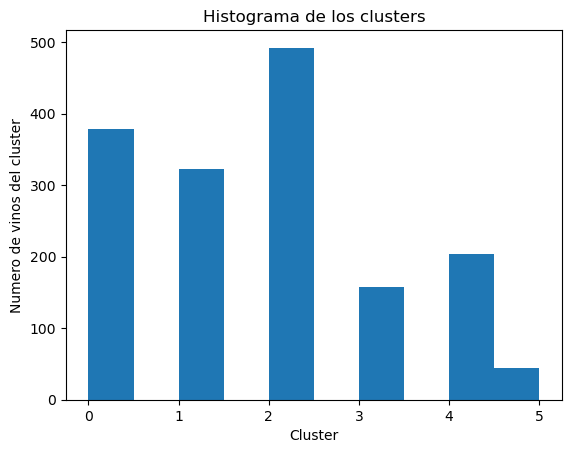

In [24]:
plt.hist(md_h)
plt.title("Histograma de los clusters")
plt.xlabel("Cluster")
plt.ylabel("Numero de vinos del cluster")

In [14]:
clus.children_

array([[   0,    4],
       [ 135,  140],
       [ 750,  751],
       ...,
       [3179, 3191],
       [3192, 3193],
       [3194, 3195]], shape=(1598, 2))

In [16]:
from scipy.cluster.hierarchy import dendrogram, linkage

In [17]:
Z = linkage(df_norm, "ward")

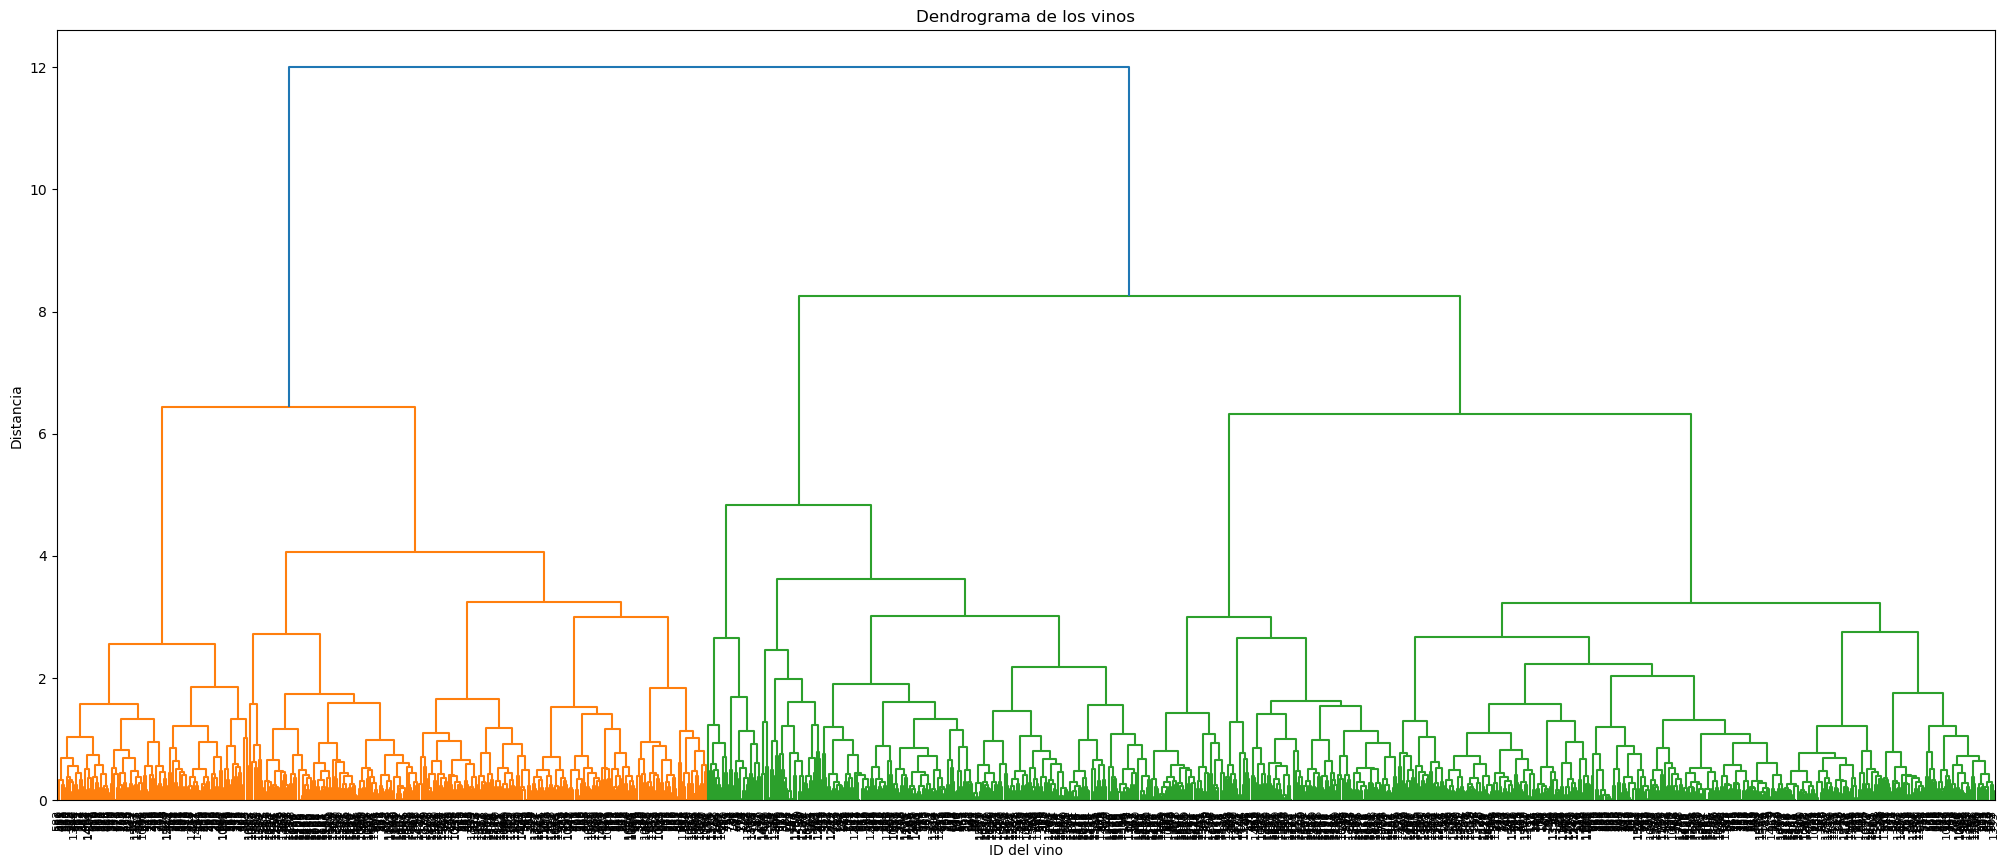

In [19]:
plt.figure(figsize=(25,10))
plt.title("Dendrograma de los vinos")
plt.xlabel("ID del vino")
plt.ylabel("Distancia")
dendrogram(Z, leaf_rotation=90., leaf_font_size=8.)
plt.show()

## K-means

In [20]:
from sklearn.cluster import KMeans
from sklearn import datasets

In [21]:
model = KMeans(n_clusters=6)
model.fit(df_norm)

C:\Users\progr\anaconda3\envs\ml-curso\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(


,n_clusters,6
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [22]:
model.labels_

array([4, 4, 4, ..., 5, 4, 1], shape=(1599,), dtype=int32)

In [25]:
md_k = pd.Series(model.labels_)

In [26]:
df_norm["clust_h"] = md_h
df_norm["clust_k"] = md_k

In [27]:
df_norm.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,clust_h,clust_k
0,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846,0.4,2,4
1,0.283186,0.520548,0.00,0.116438,0.143573,0.338028,0.215548,0.494126,0.362205,0.209581,0.215385,0.4,2,4
2,0.283186,0.438356,0.04,0.095890,0.133556,0.197183,0.169611,0.508811,0.409449,0.191617,0.215385,0.4,2,4
3,0.584071,0.109589,0.56,0.068493,0.105175,0.225352,0.190813,0.582232,0.330709,0.149701,0.215385,0.6,3,3
4,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846,0.4,2,4


(array([266.,   0., 228.,   0., 259.,   0., 194.,   0., 431., 221.]),
 array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. ]),
 <BarContainer object of 10 artists>)

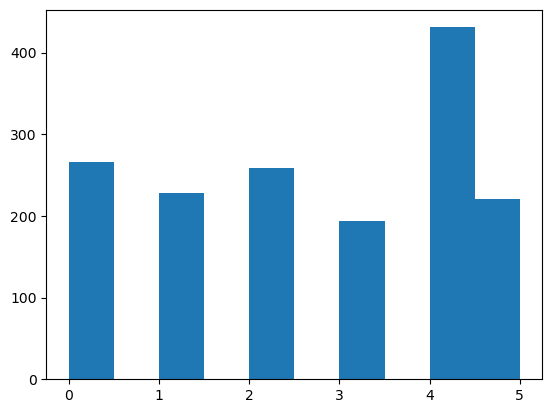

In [28]:
plt.hist(md_k)

In [29]:
model.cluster_centers_

array([[0.3132943 , 0.28580441, 0.29184211, 0.16134514, 0.1262819 ,
        0.40995976, 0.31262786, 0.536719  , 0.4336333 , 0.17878529,
        0.21710044, 0.45338346],
       [0.36946903, 0.15421473, 0.435     , 0.10841745, 0.10753302,
        0.16543118, 0.08333333, 0.40335098, 0.41245338, 0.23889064,
        0.50843455, 0.71754386],
       [0.35309393, 0.25097847, 0.35104247, 0.09507061, 0.16940074,
        0.15231932, 0.13446662, 0.54011815, 0.40662147, 0.23226135,
        0.21799822, 0.48339768],
       [0.62179546, 0.20226663, 0.54623711, 0.13864567, 0.13547493,
        0.14048207, 0.09245565, 0.67074648, 0.31090186, 0.23418112,
        0.30948982, 0.56494845],
       [0.25055951, 0.37273146, 0.08909513, 0.09210024, 0.12068064,
        0.15403091, 0.10709747, 0.48291205, 0.50198221, 0.15172902,
        0.22794336, 0.43665893],
       [0.17510912, 0.31932994, 0.09588235, 0.09334904, 0.0958158 ,
        0.24950609, 0.12474617, 0.32111415, 0.57779599, 0.18638741,
        0.49428008,

In [30]:
model.inertia_

188.588403259372

## Interpretacion final

In [31]:
df_norm.groupby("clust_k").mean()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,clust_h
clust_k,,,,,,,,,,,,,
0,0.313294,0.285804,0.291842,0.161345,0.126282,0.409960,0.312628,0.536719,0.433633,0.178785,0.217100,0.453383,1.045113
1,0.369469,0.154215,0.435000,0.108417,0.107533,0.165431,0.083333,0.403351,0.412453,0.238891,0.508435,0.717544,0.105263
2,0.353094,0.250978,0.351042,0.095071,0.169401,0.152319,0.134467,0.540118,0.406621,0.232261,0.217998,0.483398,1.552124
3,0.621795,0.202267,0.546237,0.138646,0.135475,0.140482,0.092456,0.670746,0.310902,0.234181,0.309490,0.564948,2.386598
4,0.250560,0.372731,0.089095,0.092100,0.120681,0.154031,0.107097,0.482912,0.501982,0.151729,0.227943,0.436659,2.081206
5,0.175109,0.319330,0.095882,0.093349,0.095816,0.249506,0.124746,0.321114,0.577796,0.186387,0.494280,0.614480,3.402715
